# Chapitre 13 - Exercices 13.1 à 13.4

* **13.1** : K-means et EM pour un mélange gaussien à covariance $\sigma I$ ; limite $\sigma \to 0$.
* **13.2** : rayon médian du 1-voisinage (éq. (13.7)).
* **13.3** : le théorème de Cover et Hart (éq. (13.5) et (13.12)).
* **13.4** : transformations affines d'une image et vecteurs tangents.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gammaln
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch13_prototypes as cp
set_style()
PURPLE = COLORS[6]

## Exercice 13.1 : K-means et EM pour un mélange à covariance scalaire

**Énoncé (reformulé).** On considère un mélange gaussien dont toutes les matrices de
covariance sont scalaires, $\Sigma_r = \sigma I$ pour $r = 1, \dots, R$, où $\sigma > 0$ est
**fixé** (connu). Discuter en détail l'analogie entre l'algorithme de regroupement K-means
et l'algorithme EM pour ajuster ce mélange. Montrer que lorsque $\sigma \to 0$, les deux
méthodes coïncident.

### Rappels

**Le modèle.** La densité est
$$f(x) = \sum_{r=1}^R \pi_r\, \phi_\sigma(x; \mu_r), \qquad
\phi_\sigma(x; \mu) = (2\pi\sigma)^{-p/2} \exp\Big(-\frac{\|x - \mu\|^2}{2\sigma}\Big),$$
avec des proportions $\pi_r > 0$, $\sum_r \pi_r = 1$. Ici $\sigma$ joue le rôle d'une
**variance** (c'est la notation du livre : $\Sigma_r = \sigma I$).

**K-means.** Minimise $J(C, \mu) = \sum_i \|x_i - \mu_{C(i)}\|^2$ en alternant
affectation au centre le plus proche et recalcul des centres comme moyennes.

**EM** (vu dans le cours 1, section 5.2) : on alterne le calcul des responsabilités
(étape E) et une estimation pondérée des paramètres (étape M) ; chaque itération fait
croître la log-vraisemblance $\ell(\mu, \pi) = \sum_i \log f(x_i)$.

### Les deux étapes d'EM pour ce modèle

**Étape E.** Par la formule de Bayes, la responsabilité de la composante $r$ pour
l'observation $i$ est la probabilité a posteriori que $x_i$ provienne de $r$ :
$$\gamma_{ir} = \frac{\pi_r\, \phi_\sigma(x_i; \mu_r)}{\sum_{s} \pi_s\, \phi_\sigma(x_i; \mu_s)}
= \frac{\pi_r \exp(-d_{ir}/2\sigma)}{\sum_s \pi_s \exp(-d_{is}/2\sigma)}, \qquad d_{ir} = \|x_i - \mu_r\|^2,$$
car le facteur $(2\pi\sigma)^{-p/2}$, commun à toutes les composantes, se simplifie.

**Étape M.** On maximise $\sum_i \sum_r \gamma_{ir}\big[\log \pi_r + \log \phi_\sigma(x_i; \mu_r)\big]$.
En $\mu_r$, seul compte $-\sum_i \gamma_{ir}\|x_i - \mu_r\|^2/(2\sigma)$, fonction concave
dont le gradient $\sum_i \gamma_{ir}(x_i - \mu_r)/\sigma$ s'annule en
$$\mu_r = \frac{\sum_i \gamma_{ir} x_i}{\sum_i \gamma_{ir}} .$$
En $\pi$ (sous la contrainte $\sum_r \pi_r = 1$, par un multiplicateur de Lagrange) :
$\pi_r = \frac1N \sum_i \gamma_{ir}$. Comme $\sigma$ est fixé, il n'est pas ré-estimé.

### L'analogie, étape par étape

| | K-means | EM, $\Sigma_r = \sigma I$ |
|---|---|---|
| affectation | $\gamma_{ir} = \mathbb 1\{r = \arg\min_s d_{is}\}$ (dure) | $\gamma_{ir} \propto \pi_r e^{-d_{ir}/2\sigma}$ (souple) |
| centres | moyenne du groupe | moyenne **pondérée** par les $\gamma_{ir}$ |
| critère | $J$ décroît | $\ell$ croît |

Les deux étapes du K-means sont exactement celles d'EM où l'on aurait remplacé les
responsabilités par des poids 0/1. On peut même relier les critères : si l'on fixe des
affectations dures et $\pi_r = 1/R$, la log-vraisemblance « complète »
$\sum_i \log\big[\pi_{C(i)}\phi_\sigma(x_i; \mu_{C(i)})\big]$ vaut
$-\frac{1}{2\sigma}J(C, \mu) + \text{constante}$ : maximiser l'une revient à minimiser l'autre.

Le paramètre $\sigma$ règle la « dureté » : la responsabilité dépend des **écarts**
de distances au carré, mesurés en unités de $2\sigma$.

### La limite $\sigma \to 0$

Fixons $i$ et supposons que le centre le plus proche de $x_i$, noté $r^*$, soit unique
(c'est le cas sauf pour des points exactement à égale distance de deux centres). En
divisant numérateur et dénominateur par $\pi_r e^{-d_{ir}/2\sigma}$,
$$\gamma_{ir} = \Big(1 + \sum_{s \ne r} \frac{\pi_s}{\pi_r} \exp\Big(-\frac{d_{is} - d_{ir}}{2\sigma}\Big)\Big)^{-1}.$$

* Si $r = r^*$ : pour tout $s \ne r^*$, $d_{is} - d_{ir^*} > 0$, donc
  $\exp(-(d_{is} - d_{ir^*})/2\sigma) \to 0$ quand $\sigma \to 0$ ; ainsi $\gamma_{ir^*} \to 1$.
* Si $r \ne r^*$ : le terme $s = r^*$ vérifie $d_{ir^*} - d_{ir} < 0$, donc
  $\exp(-(d_{ir^*} - d_{ir})/2\sigma) \to +\infty$ ; ainsi $\gamma_{ir} \to 0$.

(Les proportions $\pi_s/\pi_r$ sont des constantes strictement positives : elles ne
changent pas ces limites.) L'étape E devient donc **l'affectation au centre le plus
proche**, et l'étape M devient alors **le calcul des moyennes des groupes** : une
itération d'EM tend vers une itération de Lloyd.

Partant des mêmes centres initiaux, et par continuité (une composition d'un nombre fini
d'applications continues en $\sigma$ hors des cas d'égalité), les $T$ premières
itérations d'EM convergent vers celles du K-means : **les deux méthodes coïncident à la
limite**.

### Vérification numérique

Visualisons d'abord, en dimension 1 avec deux centres $\mu_1 = -1$ et $\mu_2 = 1$, la
responsabilité $\gamma_{\cdot 1}(x)$ pour plusieurs valeurs de $\sigma$ : elle tend vers
l'indicatrice $\mathbb 1\{x < 0\}$ (affectation du K-means).

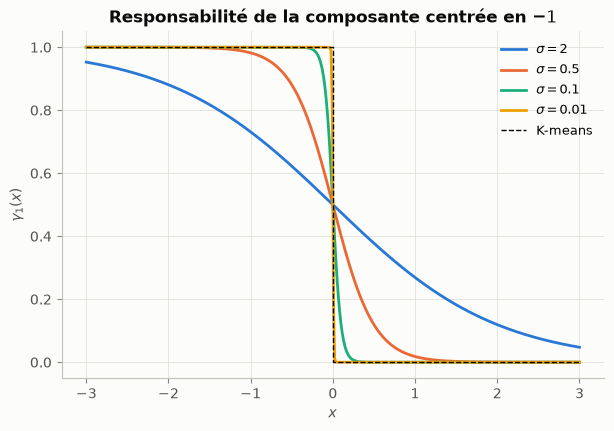

In [2]:
x = np.linspace(-3, 3, 400)
fig, ax = plt.subplots()
for s, col in zip([2.0, 0.5, 0.1, 0.01], COLORS):
    d1, d2 = (x + 1) ** 2, (x - 1) ** 2
    g1 = 1 / (1 + np.exp(-(d2 - d1) / (2 * s)))
    ax.plot(x, g1, color=col, label="$\\sigma = %g$" % s)
ax.step(x, (x < 0).astype(float), color="k", ls="--", lw=1, where="mid", label="K-means")
ax.set(title="Responsabilité de la composante centrée en $-1$",
       xlabel="$x$", ylabel="$\\gamma_1(x)$")
ax.legend()
plt.show()

Implémentons maintenant EM avec $\sigma$ fixé, et comparons-le au K-means **partant des
mêmes centres initiaux** et pour le **même nombre d'itérations** $T = 15$ (c'est exactement
l'énoncé démontré ci-dessus), sur les données « mixture » du chapitre 2.

In [3]:
def em_scalar(X, mu0, sigma, n_iter=200):
    """EM pour un mélange à covariance sigma*I fixée (moyennes et proportions estimées)."""
    mu = mu0.copy()
    pi = np.full(len(mu), 1 / len(mu))
    for _ in range(n_iter):
        D = cp.sq_dists(X, mu)
        logw = np.log(pi) - D / (2 * sigma)
        logw -= logw.max(1, keepdims=True)          # stabilité numérique
        G = np.exp(logw)
        G /= G.sum(1, keepdims=True)
        Nr = G.sum(0)
        mu = (G.T @ X) / Nr[:, None]
        pi = Nr / len(X)
    return mu, G


mix = datasets.load_mixture_example()
Xm = mix["x"]
rng = np.random.RandomState(0)
mu0 = Xm[rng.choice(len(Xm), 6, replace=False)]
T_iter = 15
C_km, lab_km, _, _ = cp.kmeans(Xm, 6, init=mu0, max_iter=T_iter)

sigmas = np.logspace(1, -5, 31)
gaps = []
for s in sigmas:
    mu_em, _ = em_scalar(Xm, mu0, s, n_iter=T_iter)
    gaps.append(np.abs(mu_em - C_km).max())

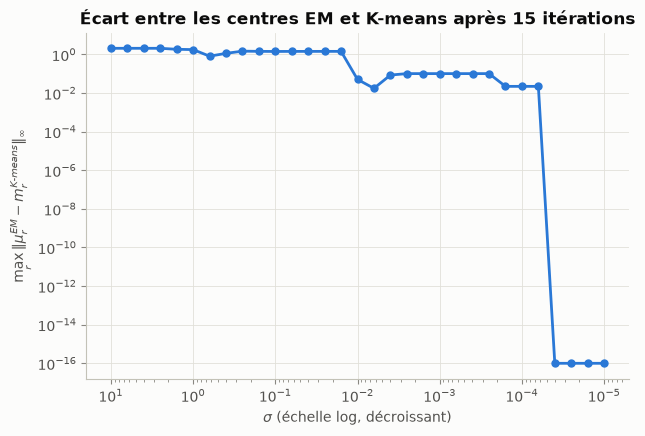

In [4]:
fig, ax = plt.subplots()
ax.loglog(sigmas, np.maximum(gaps, 1e-16), "o-", color=BLUE)
ax.invert_xaxis()
ax.set(title="Écart entre les centres EM et K-means après %d itérations" % T_iter,
       xlabel="$\\sigma$ (échelle log, décroissant)",
       ylabel="$\\max_r \\|\\mu_r^{EM} - m_r^{K\\text{-}means}\\|_\\infty$")
plt.show()

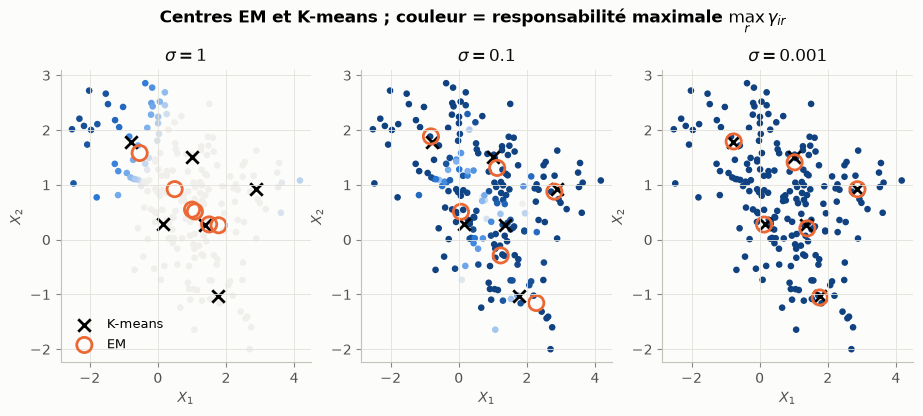

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, s in zip(axes, [1.0, 0.1, 0.001]):
    mu_em, G = em_scalar(Xm, mu0, s, n_iter=T_iter)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=G.max(1), cmap=SEQ, s=14, vmin=0.5, vmax=1)
    ax.scatter(C_km[:, 0], C_km[:, 1], marker="x", color="k", s=80, label="K-means")
    ax.scatter(mu_em[:, 0], mu_em[:, 1], marker="o", facecolors="none",
               edgecolors=ORANGE, s=120, lw=2, label="EM")
    ax.set(title="$\\sigma = %g$" % s, xlabel="$X_1$", ylabel="$X_2$")
axes[0].legend(loc="lower left")
fig.suptitle("Centres EM et K-means ; couleur = responsabilité maximale $\\max_r \\gamma_{ir}$",
             fontweight="bold", y=1.04)
plt.show()

Pour $\sigma = 1$ les responsabilités sont très partagées (couleurs claires) et les
centres EM diffèrent nettement de ceux du K-means ; pour $\sigma = 10^{-3}$ les
responsabilités valent presque toutes 1 (affectations dures) et les centres coïncident.

Le graphique de l'écart décroît par **paliers** : tant qu'un point situé presque à égale
distance de deux centres garde une responsabilité partagée, il décale légèrement les
centres. Quand $\sigma$ devient petit devant tous les écarts $d_{is} - d_{ir^*}$, l'écart
tombe à zéro (à la précision machine près).

> **À retenir.** K-means = EM « dur » pour un mélange de gaussiennes sphériques de
> même variance. L'étape E se durcit en affectation au plus proche centre quand
> $\sigma \to 0$, et l'étape M en calcul de moyennes de groupes.

## Exercice 13.2 : Rayon médian du 1-voisinage

**Énoncé (reformulé).** Établir la formule (13.7) du livre : pour $N$ points uniformes
dans le cube $[-\frac12, \frac12]^p$, le rayon $R$ du 1-voisinage de l'origine
(distance de l'origine au point le plus proche) a pour médiane
$$\operatorname{med}(R) = v_p^{-1/p}\Big(1 - \tfrac12^{1/N}\Big)^{1/p},$$
où $v_p r^p$ est le volume de la boule de rayon $r$ en dimension $p$.

### Rappels

* Le volume de la boule euclidienne de rayon $r$ dans $\mathbb R^p$ est $v_p r^p$, avec
  $v_p = \pi^{p/2}/\Gamma(p/2 + 1)$, où $\Gamma$ est la fonction Gamma
  ($\Gamma(n+1) = n!$, $\Gamma(1/2) = \sqrt\pi$) : $v_1 = 2$, $v_2 = \pi$, $v_3 = 4\pi/3$.
* Pour $X$ uniforme sur un domaine $D$ de volume 1, $\Pr(X \in A) = \operatorname{vol}(A \cap D)$.
* La **médiane** d'une variable $R$ de fonction de répartition $F$ continue et
  strictement croissante est l'unique $m$ tel que $F(m) = 1/2$.

### Solution

Notons $X_1, \dots, X_N$ les points, indépendants et uniformes sur le cube (de volume 1),
et $R = \min_i \|X_i\|$.

**Étape 1 : loi d'un seul point.** Pour $0 \le r \le \frac12$, la boule $B(0, r)$ est
contenue dans le cube (le centre du cube est à distance $\frac12$ de chaque face), donc
$$\Pr(\|X_i\| \le r) = \operatorname{vol}(B(0, r)) = v_p r^p .$$

**Étape 2 : loi du minimum.** Le minimum dépasse $r$ si et seulement si **tous** les
points sont hors de la boule ; par indépendance,
$$\Pr(R > r) = \prod_{i=1}^N \Pr(\|X_i\| > r) = (1 - v_p r^p)^N .$$

**Étape 3 : médiane.** La fonction $r \mapsto \Pr(R \le r) = 1 - (1 - v_p r^p)^N$ est
continue et strictement croissante ; la médiane $m$ résout
$$(1 - v_p m^p)^N = \tfrac12 \iff 1 - v_p m^p = \tfrac12^{1/N} \iff
m^p = \frac{1 - \frac12^{1/N}}{v_p} \iff m = v_p^{-1/p}\Big(1 - \tfrac12^{1/N}\Big)^{1/p}.$$

**Domaine de validité.** Le calcul de l'étape 1 suppose $m \le \frac12$. Si la formule
donne une valeur $> \frac12$, la boule déborde du cube, $\Pr(\|X_i\| \le r) < v_p r^p$, et la
vraie médiane est **plus grande** que la formule.

### Vérification par simulation

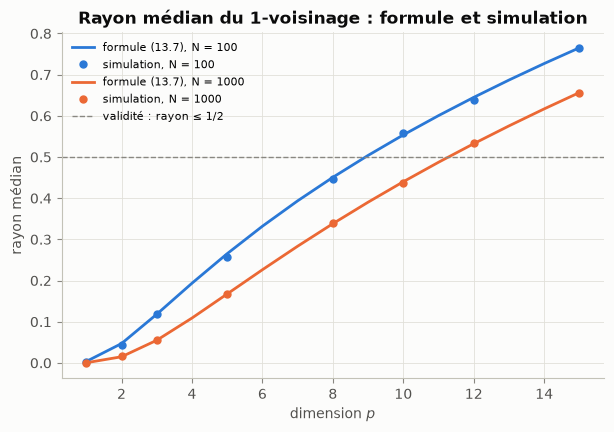

In [6]:
rng = np.random.RandomState(0)
ps = [1, 2, 3, 5, 8, 10, 12, 15]
res = {N: [] for N in (100, 1000)}
for N in res:
    for p in ps:
        R = [np.sqrt((rng.uniform(-0.5, 0.5, (N, p)) ** 2).sum(1)).min() for _ in range(400)]
        res[N].append(np.median(R))

fig, ax = plt.subplots()
pp = np.arange(1, 16)
for (N, med), col in zip(res.items(), COLORS):
    ax.plot(pp, cp.median_nn_radius(N, pp), "-", color=col, label="formule (13.7), N = %d" % N)
    ax.plot(ps, med, "o", color=col, label="simulation, N = %d" % N)
ax.axhline(0.5, color=GRAY, ls="--", lw=1, label="validité : rayon ≤ 1/2")
ax.set(title="Rayon médian du 1-voisinage : formule et simulation",
       xlabel="dimension $p$", ylabel="rayon médian")
ax.legend(fontsize=8)
plt.show()

In [7]:
for N in res:
    for p, m in zip(ps, res[N]):
        print("N=%5d p=%2d  simulation %.3f  formule %.3f" % (N, p, m, cp.median_nn_radius(N, p)))

N=  100 p= 1  simulation 0.003  formule 0.003
N=  100 p= 2  simulation 0.045  formule 0.047
N=  100 p= 3  simulation 0.119  formule 0.118
N=  100 p= 5  simulation 0.257  formule 0.265
N=  100 p= 8  simulation 0.447  formule 0.451
N=  100 p=10  simulation 0.559  formule 0.554
N=  100 p=12  simulation 0.638  formule 0.645
N=  100 p=15  simulation 0.764  formule 0.765
N= 1000 p= 1  simulation 0.000  formule 0.000
N= 1000 p= 2  simulation 0.016  formule 0.015
N= 1000 p= 3  simulation 0.056  formule 0.055
N= 1000 p= 5  simulation 0.167  formule 0.167
N= 1000 p= 8  simulation 0.339  formule 0.338
N= 1000 p=10  simulation 0.436  formule 0.440
N= 1000 p=12  simulation 0.533  formule 0.532
N= 1000 p=15  simulation 0.657  formule 0.657


L'accord est excellent. Même au-delà de $1/2$, où la formule n'est plus exacte en
théorie, l'écart reste invisible : en grande dimension, un point uniforme dans une boule
de rayon $r$ a des coordonnées typiquement de l'ordre de $r/\sqrt p$, bien inférieures à
$1/2$, de sorte que la partie de la boule qui déborde du cube a un volume relatif
minuscule.

> **À retenir.** $\Pr(R > r) = (1 - v_p r^p)^N$ : pour que le plus proche voisin soit à
> distance $r$, il faut $N \approx 1/(v_p r^p)$ points, nombre qui explose
> exponentiellement avec $p$. C'est le fléau de la dimension pour les k-ppv.

## Exercice 13.3 : Le théorème de Cover et Hart

**Énoncé (reformulé).** Soit $E^*$ l'erreur de la règle de Bayes dans un problème à
$K$ classes de probabilités conditionnelles $p_k(x)$, et $k^* = \arg\max_k p_k(x)$. En
supposant que le point test et le point d'apprentissage le plus proche ont les mêmes
caractéristiques $x$, montrer (éq. (13.5))
$$\sum_{k=1}^K p_k(x)\big(1 - p_k(x)\big) \le 2\big(1 - p_{k^*}(x)\big) - \frac{K}{K-1}\big(1 - p_{k^*}(x)\big)^2 .$$
En déduire que l'erreur du 1-ppv converge (dans $L^1$), quand la taille de
l'échantillon croît, vers une valeur $E_1$ majorée par (éq. (13.12))
$$E_1 \le E^*\Big(2 - \frac{K}{K-1}E^*\Big).$$

### Rappels

* **Inégalité de Cauchy–Schwarz** dans $\mathbb R^m$ : $\big(\sum_{j=1}^m a_j b_j\big)^2 \le
  \big(\sum a_j^2\big)\big(\sum b_j^2\big)$. Avec $b_j = 1$ :
  $\big(\sum_{j=1}^m a_j\big)^2 \le m \sum_{j=1}^m a_j^2$.
* **Inégalité de Jensen** (cas de la variance) : $\mathbb E[Z^2] \ge (\mathbb E[Z])^2$,
  puisque $\operatorname{Var}(Z) = \mathbb E[Z^2] - (\mathbb E Z)^2 \ge 0$.
* **Convergence dominée** : si $Z_N \to Z$ presque sûrement (ou en probabilité) et
  $|Z_N| \le 1$, alors $\mathbb E|Z_N - Z| \to 0$.

### Étape 1 : l'erreur ponctuelle du 1-ppv

Au point $x$, l'étiquette $G$ du point test et l'étiquette $G'$ du voisin (situé au même
$x$) sont **indépendantes** et de même loi $(p_1(x), \dots, p_K(x))$. Le 1-ppv se trompe
si $G' \ne G$ :
$$\Pr(G' \ne G) = 1 - \sum_k \Pr(G = k, G' = k) = 1 - \sum_k p_k^2 = \sum_k p_k(1 - p_k),$$
en utilisant $\sum_k p_k = 1$ (on écrit $p_k$ pour $p_k(x)$).

### Étape 2 : l'inégalité (13.5)

Notons $p^* = p_{k^*}$ et $q = 1 - p^* = \sum_{k \ne k^*} p_k$. On isole le terme $k^*$ :
$$\sum_k p_k(1 - p_k) = 1 - p^{*2} - \sum_{k \ne k^*} p_k^2 .$$
Par Cauchy–Schwarz appliqué aux $K - 1$ nombres $p_k$, $k \ne k^*$ :
$$\sum_{k \ne k^*} p_k^2 \ge \frac{1}{K-1}\Big(\sum_{k \ne k^*} p_k\Big)^2 = \frac{q^2}{K-1}.$$
Donc
$$\sum_k p_k(1 - p_k) \le 1 - (1 - q)^2 - \frac{q^2}{K-1} = 2q - q^2 - \frac{q^2}{K-1} = 2q - \frac{K}{K-1}q^2,$$
ce qui est exactement (13.5). Il y a égalité quand les $K-1$ classes non dominantes ont
la même probabilité (cas d'égalité de Cauchy–Schwarz).

### Étape 3 : convergence de l'erreur du 1-ppv

Fixons un point test $x$ du support de la loi de $X$ et notons $x_{(1)}$ son plus proche
voisin parmi $N$ points d'apprentissage indépendants.

1. **Le voisin se rapproche.** Pour tout $\delta > 0$, la boule $B(x, \delta)$ a une
   probabilité $q_\delta > 0$ (car $x$ est dans le support), donc
   $\Pr(\|x_{(1)} - x\| > \delta) = (1 - q_\delta)^N \to 0$ : $x_{(1)} \to x$ en probabilité.
2. **Erreur conditionnelle.** Sachant $x$ et $x_{(1)}$, les étiquettes sont
   indépendantes, et l'erreur vaut
   $e_N(x) = \sum_k p_k(x)\big(1 - p_k(x_{(1)})\big)$.
3. **Passage à la limite.** Si les $p_k$ sont continues, $e_N(x) \to \sum_k p_k(x)(1 - p_k(x))$
   en probabilité ; comme $0 \le e_N \le 1$, la convergence dominée donne la
   convergence **dans $L^1$** de l'erreur, puis (en intégrant en $x$)
   $$E_1 = \lim_N \mathbb E[e_N(X)] = \mathbb E\Big[\sum_k p_k(X)(1 - p_k(X))\Big].$$

Le livre renvoie à Ripley (1996, chap. 6) pour une preuve complète (elle traite aussi le
cas où les $p_k$ ne sont pas continues).

### Étape 4 : la borne (13.12)

L'erreur de Bayes est $E^* = \mathbb E[1 - p_{k^*}(X)] = \mathbb E[q(X)]$. En intégrant (13.5),
$$E_1 \le 2\mathbb E[q(X)] - \frac{K}{K-1}\mathbb E[q(X)^2] \le 2E^* - \frac{K}{K-1}(E^*)^2 = E^*\Big(2 - \frac{K}{K-1}E^*\Big),$$
la seconde inégalité venant de Jensen : $\mathbb E[q^2] \ge (\mathbb E q)^2 = E^{*2}$
(et du signe $-$ devant). Par ailleurs, $\sum_k p_k(1-p_k) \ge 1 - p^*$ (car
$\sum_k p_k^2 \le p^* \sum_k p_k = p^*$), donc $E^* \le E_1$ : le 1-ppv ne fait jamais mieux
que Bayes et, asymptotiquement, jamais plus de deux fois pire.

### Vérifications numériques

**(a) L'inégalité (13.5)** sur des vecteurs de probabilités tirés au hasard ($K = 3$),
et sa borne en fonction de $q = 1 - p^*$.

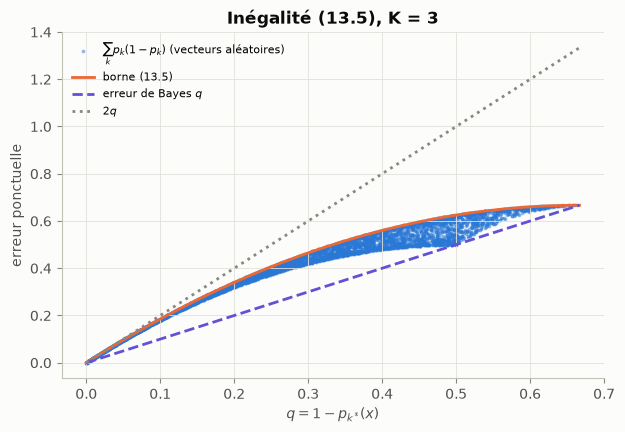

inégalité violée ? False


In [8]:
rng = np.random.RandomState(0)
K = 3
P = rng.dirichlet(np.full(K, 0.5), size=5000)
lhs = (P * (1 - P)).sum(1)
q = 1 - P.max(1)
qq = np.linspace(0, (K - 1) / K, 200)
fig, ax = plt.subplots()
ax.scatter(q, lhs, s=3, color=BLUE, alpha=0.4, label="$\\sum_k p_k(1-p_k)$ (vecteurs aléatoires)")
ax.plot(qq, 2 * qq - K / (K - 1) * qq ** 2, color=ORANGE, label="borne (13.5)")
ax.plot(qq, qq, color=PURPLE, ls="--", label="erreur de Bayes $q$")
ax.plot(qq, 2 * qq, color=GRAY, ls=":", label="$2q$")
ax.set(title="Inégalité (13.5), K = 3", xlabel="$q = 1 - p_{k^*}(x)$",
       ylabel="erreur ponctuelle")
ax.legend(fontsize=8)
plt.show()
print("inégalité violée ?", np.any(lhs > 2 * q - K / (K - 1) * q ** 2 + 1e-12))

**(b) Convergence de l'erreur du 1-ppv.** Problème à $K = 3$ classes en dimension 1 :
$X$ uniforme sur $[0, 1]$ et $p_k(x) \propto \exp\big(-(x - c_k)^2/0{,}04\big)$ avec
$c = (0{,}2;\ 0{,}5;\ 0{,}8)$ (normalisé pour que $\sum_k p_k = 1$). Nous
calculons $E^*$, $E_1$ et la borne par intégration numérique, et simulons l'erreur du
1-ppv pour des $N$ croissants.

In [9]:
def probs(x):
    W = np.exp(-(x[:, None] - np.array([0.2, 0.5, 0.8])) ** 2 / 0.04)
    return W / W.sum(1, keepdims=True)


xs = np.linspace(0, 1, 200001)
Px = probs(xs)
E_star = np.mean(1 - Px.max(1))
E_1 = np.mean((Px * (1 - Px)).sum(1))
bound = E_star * (2 - K / (K - 1) * E_star)
print("E* = %.4f   E1 = %.4f   borne = %.4f" % (E_star, E_1, bound))


def draw(n, rng):
    x = rng.uniform(size=n)
    u = rng.uniform(size=n)[:, None]
    g = (u > probs(x).cumsum(1)).sum(1)
    return x, g


Ns = [10, 30, 100, 300, 1000, 3000, 10000]
emp = []
for N in Ns:
    e = []
    for rep in range(30):
        x, g = draw(N, rng)
        xt, gt = draw(2000, rng)
        order = np.argsort(x)
        pos = np.clip(np.searchsorted(x[order], xt), 1, N - 1)
        left, right = order[pos - 1], order[pos]
        nn = np.where(np.abs(xt - x[left]) < np.abs(xt - x[right]), left, right)
        e.append(np.mean(g[nn] != gt))
    emp.append(np.mean(e))

E* = 0.1789   E1 = 0.2533   borne = 0.3098


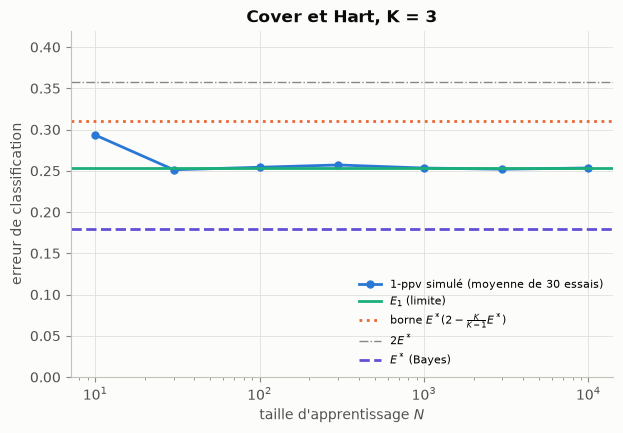

In [10]:
fig, ax = plt.subplots()
ax.semilogx(Ns, emp, "o-", color=BLUE, label="1-ppv simulé (moyenne de 30 essais)")
ax.axhline(E_1, color=COLORS[2], label="$E_1$ (limite)")
ax.axhline(bound, color=ORANGE, ls=":", label="borne $E^*(2 - \\frac{K}{K-1}E^*)$")
ax.axhline(2 * E_star, color=GRAY, ls="-.", lw=1, label="$2E^*$")
ax.axhline(E_star, color=PURPLE, ls="--", label="$E^*$ (Bayes)")
ax.set(title="Cover et Hart, K = 3", xlabel="taille d'apprentissage $N$",
       ylabel="erreur de classification", ylim=(0, 0.42))
ax.legend(fontsize=8, loc="lower right")
plt.show()

> **À retenir.** Asymptotiquement, $E^* \le E_1 \le E^*\big(2 - \frac{K}{K-1}E^*\big) \le 2E^*$.
> La preuve repose sur Cauchy–Schwarz (pour la borne ponctuelle) et Jensen (pour
> l'intégration). La convergence demande que le voisin se rapproche du point test :
> c'est l'hypothèse « biais nul », réaliste en petite dimension seulement.

## Exercice 13.4 : Transformations affines d'une image

**Énoncé (reformulé).** On voit une image comme une fonction $F : \mathbb R^2 \to \mathbb R$
(niveau de gris en chaque point du papier). Alors $x \mapsto F(c + x_0 + A(x - x_0))$ est
une transformation affine de l'image, $A$ étant une matrice $2 \times 2$ et $c$ un vecteur
de translation.

1. Décomposer $A$ (par une factorisation QR) de façon à faire apparaître les paramètres
   des quatre transformations affines : deux homothéties, un cisaillement et une rotation.
2. Par la règle de dérivation des fonctions composées, montrer que la dérivée de
   $F(c + x_0 + A(x - x_0))$ par rapport à chacun de ces paramètres s'exprime à l'aide des
   deux dérivées spatiales de $F$.
3. À l'aide d'un lisseur à noyau bidimensionnel (chapitre 6), décrire comment mettre en
   œuvre ce calcul pour des images quantifiées en $16 \times 16$ pixels.

### Question 1 : décomposition QR

**Rappel.** Toute matrice inversible $A$ s'écrit $A = QR$ avec $Q$ orthogonale et $R$
triangulaire supérieure à diagonale strictement positive (c'est l'orthonormalisation de
Gram–Schmidt des colonnes de $A$), et cette écriture est unique.

Pour une transformation qui conserve l'orientation ($\det A > 0$, une écriture manuscrite
n'est pas « retournée en miroir »), $\det Q = \det A / \det R > 0$ donc $Q$ est une
**rotation** $Q = R_\theta = \begin{pmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{pmatrix}$.
Puis on factorise la partie triangulaire :
$$R = \begin{pmatrix} s_1 & h\\ 0 & s_2\end{pmatrix}
= \begin{pmatrix} s_1 & 0\\ 0 & s_2\end{pmatrix}\begin{pmatrix} 1 & \kappa\\ 0 & 1\end{pmatrix},
\qquad \kappa = h / s_1 .$$
D'où
$$A = R_\theta \, \operatorname{diag}(s_1, s_2)\, \begin{pmatrix} 1 & \kappa\\ 0 & 1\end{pmatrix}$$
avec quatre paramètres : $\theta$ (rotation), $s_1, s_2$ (homothéties selon chaque axe),
$\kappa$ (cisaillement). L'identité correspond à $\theta = 0$, $s_1 = s_2 = 1$, $\kappa = 0$.
Avec les deux paramètres de translation $c$, on obtient les 6 paramètres d'une
transformation affine du plan.

In [11]:
rng = np.random.RandomState(1)
A = np.array([[1.1, 0.3], [-0.2, 0.9]])
Q, Rm = np.linalg.qr(A)
S = np.diag(np.sign(np.diag(Rm)))          # on impose une diagonale positive
Q, Rm = Q @ S, S @ Rm
theta = np.arctan2(Q[1, 0], Q[0, 0])
s1, s2, kappa = Rm[0, 0], Rm[1, 1], Rm[0, 1] / Rm[0, 0]
A_rec = cp.rotation_matrix(theta) @ np.diag([s1, s2]) @ np.array([[1, kappa], [0, 1]])
print("theta = %.3f rad, s1 = %.3f, s2 = %.3f, kappa = %.3f" % (theta, s1, s2, kappa))
print("reconstruction exacte :", np.allclose(A_rec, A))

theta = -0.180 rad, s1 = 1.118, s2 = 0.939, kappa = 0.120
reconstruction exacte : True


### Question 2 : dérivées par rapport aux paramètres

Posons $u = x - x_0$ (coordonnées relatives au centre $x_0$ de l'image) et
$G_\lambda(x) = F\big(c + x_0 + A_\lambda u\big)$ où $\lambda$ est l'un des paramètres. Par la
règle de dérivation des fonctions composées,
$$\frac{\partial G_\lambda(x)}{\partial \lambda} = \nabla F\big(c + x_0 + A u\big)^T\Big(\frac{\partial c}{\partial\lambda} + \frac{\partial A}{\partial\lambda} u\Big),$$
où $\nabla F = (F_1, F_2)$ est le vecteur des deux **dérivées spatiales** de l'image.
À l'identité ($c = 0$, $A = I$), $\nabla F$ est évalué en $x$ lui-même et :

| paramètre | $\partial A / \partial\lambda$ ou $\partial c / \partial \lambda$ | dérivée de l'image |
|---|---|---|
| translation $c_1$ | $\partial c = (1, 0)$ | $F_1(x)$ |
| translation $c_2$ | $\partial c = (0, 1)$ | $F_2(x)$ |
| rotation $\theta$ | $\begin{pmatrix}0 & -1\\ 1 & 0\end{pmatrix}$ | $-u_2 F_1(x) + u_1 F_2(x)$ |
| homothétie $s_1$ | $\begin{pmatrix}1 & 0\\ 0 & 0\end{pmatrix}$ | $u_1 F_1(x)$ |
| homothétie $s_2$ | $\begin{pmatrix}0 & 0\\ 0 & 1\end{pmatrix}$ | $u_2 F_2(x)$ |
| cisaillement $\kappa$ | $\begin{pmatrix}0 & 1\\ 0 & 0\end{pmatrix}$ | $u_2 F_1(x)$ |

(Pour la rotation : $\frac{d}{d\theta}R_\theta\big|_{\theta=0} = \begin{pmatrix}-\sin 0 & -\cos 0\\ \cos 0 & -\sin 0\end{pmatrix}$.)
Toutes ces dérivées sont des combinaisons de $F_1$ et $F_2$ à coefficients polynomiaux
en $u$ : ce sont les **vecteurs tangents** utilisés par la distance tangente.
Hors de l'identité, la même formule vaut avec $\nabla F$ évalué au point transformé.

### Question 3 : mise en œuvre sur une image $16 \times 16$

Une image quantifiée ne donne $F$ qu'aux centres $u_j$ des 256 pixels ; on ne peut pas la
dériver directement. On la prolonge en une fonction lisse par un **lisseur à noyau de
Nadaraya–Watson** (chapitre 6) avec un noyau gaussien de largeur $h$ :
$$\hat F(u) = \frac{\sum_j K_h(u - u_j) F_j}{\sum_j K_h(u - u_j)}, \qquad K_h(t) = \exp\Big(-\frac{\|t\|^2}{2h^2}\Big).$$

Ses dérivées se calculent exactement (règle du quotient) : avec
$\partial_1 K_h(u - u_j) = -\frac{u_1 - u_{j1}}{h^2} K_h(u - u_j)$,
$$\hat F_1(u) = \frac{\sum_j \partial_1 K_h(u - u_j) F_j}{\sum_j K_h(u - u_j)} - \hat F(u)\,\frac{\sum_j \partial_1 K_h(u - u_j)}{\sum_j K_h(u - u_j)},$$
et de même pour $\hat F_2$.

Point clé : $\hat F$, $\hat F_1$, $\hat F_2$ évalués aux 256 pixels sont **linéaires en
l'image** : $\hat F_1 = S_1 F$, $\hat F_2 = S_2 F$ avec des matrices $256 \times 256$
fixes, calculées une fois pour toutes. Les vecteurs tangents s'obtiennent alors par
produits matriciels pour toutes les images à la fois (fonctions
`cp.smoother_matrices` et `cp.image_tangents`). La largeur $h$ règle le compromis
entre fidélité à l'image (petit $h$) et régularité des dérivées (grand $h$).

### Vérification numérique

Pour chaque transformation, nous comparons le vecteur tangent analytique à une
**différence finie centrée** $\big[G_{+a} - G_{-a}\big]/(2a)$, où les images transformées
$G_{\pm a}$ sont obtenues en évaluant $\hat F$ aux points $c + A u_j$.

In [12]:
Xz, yz = datasets.load_zip("train")
img = Xz[np.where(yz == 2)[0][0]]
h = 0.8
a = 1e-3
transfos = {
    "translation x": (np.eye(2), (a, 0)),
    "translation y": (np.eye(2), (0, a)),
    "rotation": (cp.rotation_matrix(a), (0, 0)),
    "homothétie x": (np.diag([1 + a, 1]), (0, 0)),
    "homothétie y": (np.diag([1, 1 + a]), (0, 0)),
    "cisaillement": (np.array([[1, a], [0, 1]]), (0, 0)),
}
T = cp.image_tangents(img, which=tuple(transfos), h=h)[0]
fd = []
for name, (A_, c_) in transfos.items():
    A_m = 2 * np.eye(2) - A_                          # transformation de paramètre -a
    gp = cp.transform_image(img, A_, c_, h=h)
    gm = cp.transform_image(img, A_m, -np.asarray(c_), h=h)
    fd.append((gp - gm) / (2 * a))
for name, t, f in zip(transfos, T, fd):
    print("%-14s corrélation(analytique, diff. finie) = %.6f" % (name, np.corrcoef(t, f)[0, 1]))

translation x  corrélation(analytique, diff. finie) = 1.000000
translation y  corrélation(analytique, diff. finie) = 1.000000
rotation       corrélation(analytique, diff. finie) = 1.000000
homothétie x   corrélation(analytique, diff. finie) = 1.000000
homothétie y   corrélation(analytique, diff. finie) = 1.000000
cisaillement   corrélation(analytique, diff. finie) = 1.000000


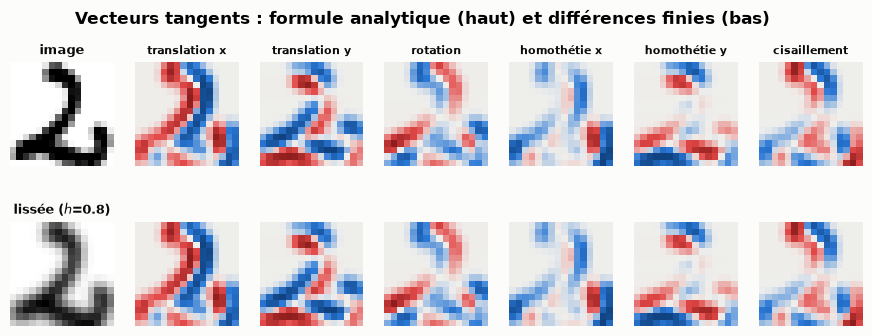

In [13]:
fig, axes = plt.subplots(2, 7, figsize=(11, 3.8))
axes[0, 0].imshow(img.reshape(16, 16), cmap="gray_r")
axes[0, 0].set_title("image", fontsize=9)
axes[1, 0].imshow(cp.transform_image(img, h=h).reshape(16, 16), cmap="gray_r")
axes[1, 0].set_title("lissée ($h$=%.1f)" % h, fontsize=9)
for j, (name, t, f) in enumerate(zip(transfos, T, fd), start=1):
    m = np.abs(t).max()
    axes[0, j].imshow(t.reshape(16, 16), cmap=DIV, vmin=-m, vmax=m)
    axes[0, j].set_title(name, fontsize=8)
    axes[1, j].imshow(f.reshape(16, 16), cmap=DIV, vmin=-m, vmax=m)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Vecteurs tangents : formule analytique (haut) et différences finies (bas)",
             fontweight="bold")
plt.show()

Les deux calculs coïncident (corrélations égales à 1 à $10^{-6}$ près) : la règle de
dérivation des fonctions composées appliquée au lissage à noyau donne bien les dérivées
des images transformées.

> **À retenir.** $A = R_\theta\,\mathrm{diag}(s_1, s_2)\begin{pmatrix}1&\kappa\\0&1\end{pmatrix}$
> sépare rotation, homothéties et cisaillement. Chaque vecteur tangent est une
> combinaison des deux dérivées spatiales $F_1, F_2$, que l'on obtient sur une image
> pixellisée grâce à un lisseur à noyau, de façon linéaire en l'image.